<a href="https://colab.research.google.com/github/AlienXs9/Autism-Facial-Emotion-Recognition-/blob/main/Submission_2_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Submission 2: Pretrained CNNs: Feature Extraction vs Fine-Tuning

**3 models x 2 modes = 6 runs.** Models: MobileNetV2, ResNet50, EfficientNet-B0 (all pretrained on ImageNet).

* **Feature extraction** = freeze the pretrained model, train only the new final layer.
* **Fine-tuning** = also unfreeze the last few layers and train them with a smaller learning rate.


## Step 1 · Imports

In [ ]:
import os, time, zipfile, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms as T

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


## Step 2 · Settings (change things here)

In [ ]:
ZIP_PATH = "/content/archive.zip"
DATA_DIR = "/content/dataset"

QUICK_TEST = False
MAX_EPOCHS = 30
PATIENCE   = 5
BATCH_SIZE = 32
SEED       = 42


LR_FEATURE_EXTRACTION = 1e-3
LR_FINE_TUNING        = 1e-4

MODEL_NAMES = ["mobilenet_v2", "resnet50", "efficientnet_b0"]

if QUICK_TEST:
    MAX_EPOCHS, PATIENCE = 2, 2

torch.manual_seed(SEED); np.random.seed(SEED)

## Step 3 · Load the images and split 80 / 10 / 10

In [ ]:

if ZIP_PATH and os.path.exists(ZIP_PATH) and not os.path.isdir(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)


rows = []
for folder, _, files in os.walk(DATA_DIR):
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            rows.append((os.path.join(folder, f), os.path.basename(folder)))


df = pd.DataFrame(rows, columns=["path", "class_name"])
class_names = sorted(df["class_name"].unique())
df["label"] = df["class_name"].map({c: i for i, c in enumerate(class_names)})
NUM_CLASSES = len(class_names)

print(len(df), "images,", NUM_CLASSES, "classes:", class_names)
print(df["class_name"].value_counts())

7600 images, 6 classes: ['Natural', 'anger', 'fear', 'joy', 'sadness', 'surprise']
class_name
joy         3500
sadness     2000
anger        690
surprise     630
Natural      480
fear         300
Name: count, dtype: int64


In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.20, stratify=df["label"], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

if QUICK_TEST:
    train_df = train_df.groupby("label").head(20)
    val_df   = val_df.groupby("label").head(5)
    test_df  = test_df.groupby("label").head(5)

print("train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))


counts = train_df["label"].value_counts().sort_index().values
class_weights = torch.tensor(len(train_df) / (NUM_CLASSES * counts), dtype=torch.float32)
print("class weights:", class_weights.numpy().round(2))

train: 6080 | val: 760 | test: 760
class weights: [2.64 1.84 4.22 0.36 0.63 2.01]


## Step 4 · Preprocessing and augmentation

* **All images:** resize to 224x224 and normalise with ImageNet mean/std.
* **Training images only:** random flip, small rotation, small colour change. The model sees a slightly different version
  of each image every epoch, so it cannot just memorise them (as the dataset is small).

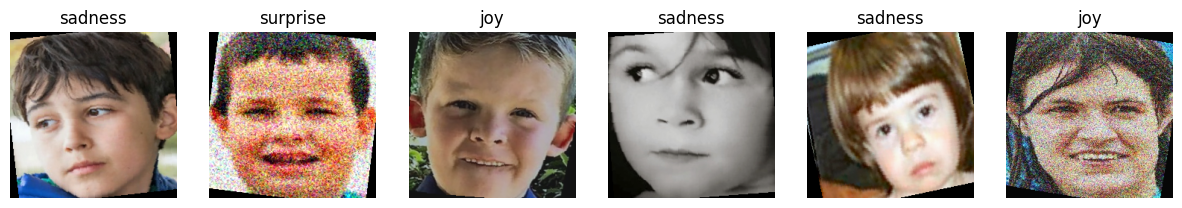

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tfm = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tfm = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])



class ImageDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.paths  = dataframe["path"].tolist()
        self.labels = dataframe["label"].tolist()
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]



train_loader = DataLoader(ImageDataset(train_df, train_tfm), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(ImageDataset(val_df,   eval_tfm),  batch_size=BATCH_SIZE, num_workers=2)
test_loader  = DataLoader(ImageDataset(test_df,  eval_tfm),  batch_size=BATCH_SIZE, num_workers=2)



imgs, labs = next(iter(train_loader))
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, im, lb in zip(axes, imgs, labs):
    im = (im * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1)
    ax.imshow(im.permute(1, 2, 0)); ax.set_title(class_names[lb]); ax.axis("off")
plt.show()

## Step 5 · Build a model

`build_model(name, mode)` loads a pretrained model, replaces its last layer with one that has our number of classes,
and decides which layers are allowed to learn


In [ ]:
def build_model(name, mode):
    # 1) load pretrained model and swap the last layer for our classes
    if name == "mobilenet_v2":
        model = models.mobilenet_v2(weights="IMAGENET1K_V1")
        model.classifier[1] = nn.Linear(model.last_channel, NUM_CLASSES)
        last_blocks = [model.features[-3:]]            # last 3 blocks
    elif name == "resnet50":
        model = models.resnet50(weights="IMAGENET1K_V1")
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        last_blocks = [model.layer4]                   # last stage
    elif name == "efficientnet_b0":
        model = models.efficientnet_b0(weights="IMAGENET1K_V1")
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
        last_blocks = [model.features[-2:]]            # last 2 blocks
    last_layer = model.classifier[1] if name != "resnet50" else model.fc

    # 2) freeze everything
    for p in model.parameters():
        p.requires_grad = False
    # 3) always train the new last layer
    for p in last_layer.parameters():
        p.requires_grad = True
    # 4) for fine-tuning, also unfreeze the last block(s)
    if mode == "fine_tuning":
        for block in last_blocks:
            for p in block.parameters():
                p.requires_grad = True
    return model.to(device)

## Step 6 · Training function (used for all 6 runs)


In [ ]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out  = model(x)
            loss = loss_fn(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct    += (out.argmax(1) == y).sum().item()
            n          += len(y)
    return total_loss / n, correct / n


def train_model(model, lr):
    params    = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr)
    loss_fn   = nn.CrossEntropyLoss(weight=class_weights.to(device))

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss, best_weights, wait = float("inf"), None, 0

    start = time.time()
    for epoch in range(MAX_EPOCHS):
        tr_loss, tr_acc = run_epoch(model, train_loader, loss_fn, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, loss_fn)
        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
        print(f"Epoch {epoch+1:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")

        if va_loss < best_val_loss:
            best_val_loss, best_weights, wait = va_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:
                print("Early stopping.")
                break

    train_time = time.time() - start
    model.load_state_dict(best_weights)
    return history, train_time

## Step 7 · Evaluation function (test set)

In [ ]:
def evaluate(model):
    model.eval()
    preds, labels = [], []
    start = time.time()
    with torch.no_grad():
        for x, y in test_loader:
            out = model(x.to(device))
            preds += out.argmax(1).cpu().tolist()
            labels += y.tolist()
    test_time = time.time() - start
    return np.array(labels), np.array(preds), test_time


def show_results(title, history, labels, preds):
    # accuracy + loss curves
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history["train_acc"], label="train"); ax[0].plot(history["val_acc"], label="validation")
    ax[0].set_title(title + " - accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(history["train_loss"], label="train"); ax[1].plot(history["val_loss"], label="validation")
    ax[1].set_title(title + " - loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.show()

    print(classification_report(labels, preds, target_names=class_names, digits=3, zero_division=0))

    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title(title + " - confusion matrix (test set)"); plt.xlabel("predicted"); plt.ylabel("true")
    plt.show()

## Step 8 · Run all 6 experiments



mobilenet_v2 | feature_extraction
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 54.4MB/s]


Epoch  1 | train loss 1.732 acc 0.284 | val loss 1.557 acc 0.462
Epoch  2 | train loss 1.531 acc 0.384 | val loss 1.470 acc 0.357
Epoch  3 | train loss 1.485 acc 0.404 | val loss 1.416 acc 0.451
Epoch  4 | train loss 1.441 acc 0.410 | val loss 1.398 acc 0.536
Epoch  5 | train loss 1.393 acc 0.444 | val loss 1.366 acc 0.425
Epoch  6 | train loss 1.388 acc 0.436 | val loss 1.325 acc 0.525
Epoch  7 | train loss 1.379 acc 0.443 | val loss 1.318 acc 0.413
Epoch  8 | train loss 1.345 acc 0.456 | val loss 1.410 acc 0.480
Epoch  9 | train loss 1.323 acc 0.454 | val loss 1.307 acc 0.489
Epoch 10 | train loss 1.361 acc 0.450 | val loss 1.271 acc 0.482
Epoch 11 | train loss 1.322 acc 0.456 | val loss 1.291 acc 0.530
Epoch 12 | train loss 1.337 acc 0.466 | val loss 1.304 acc 0.463
Epoch 13 | train loss 1.332 acc 0.461 | val loss 1.291 acc 0.537
Epoch 14 | train loss 1.318 acc 0.471 | val loss 1.317 acc 0.549
Epoch 15 | train loss 1.353 acc 0.461 | val loss 1.291 acc 0.536
Early stopping.


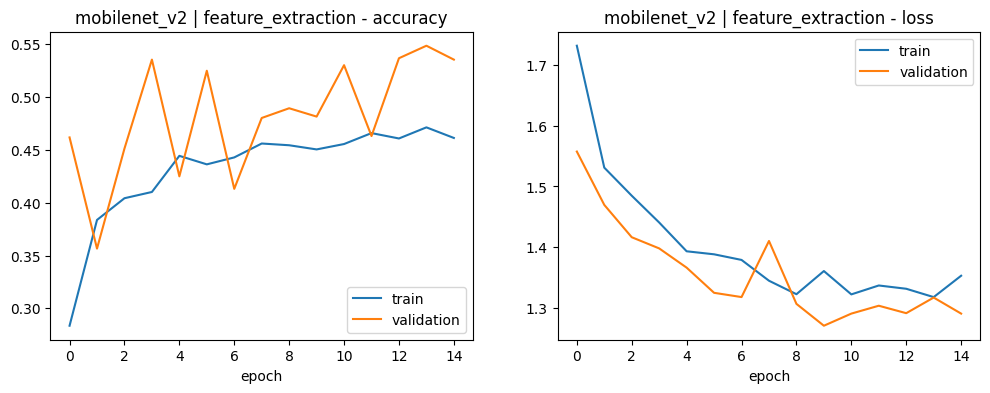

              precision    recall  f1-score   support

     Natural      0.450     0.375     0.409        48
       anger      0.299     0.580     0.394        69
        fear      0.214     0.700     0.328        30
         joy      0.856     0.494     0.627       350
     sadness      0.384     0.280     0.324       200
    surprise      0.243     0.540     0.335        63

    accuracy                          0.450       760
   macro avg      0.408     0.495     0.403       760
weighted avg      0.579     0.450     0.476       760



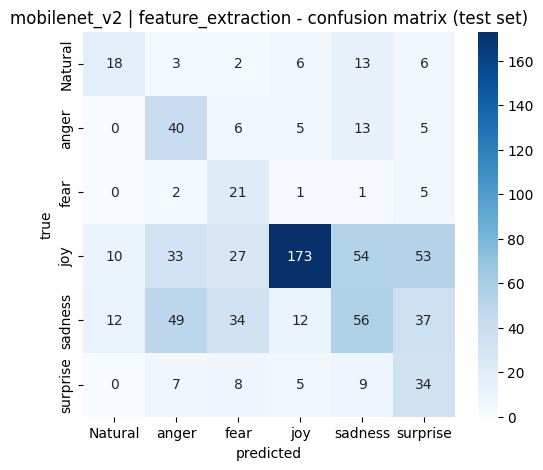


mobilenet_v2 | fine_tuning
Epoch  1 | train loss 1.538 acc 0.388 | val loss 1.243 acc 0.522
Epoch  2 | train loss 1.177 acc 0.532 | val loss 1.065 acc 0.575
Epoch  3 | train loss 0.975 acc 0.599 | val loss 0.906 acc 0.609
Epoch  4 | train loss 0.850 acc 0.638 | val loss 0.886 acc 0.633
Epoch  5 | train loss 0.768 acc 0.674 | val loss 0.762 acc 0.658
Epoch  6 | train loss 0.706 acc 0.694 | val loss 0.821 acc 0.643
Epoch  7 | train loss 0.660 acc 0.711 | val loss 0.702 acc 0.717
Epoch  8 | train loss 0.632 acc 0.721 | val loss 0.745 acc 0.716
Epoch  9 | train loss 0.599 acc 0.737 | val loss 0.665 acc 0.711
Epoch 10 | train loss 0.580 acc 0.751 | val loss 0.595 acc 0.716
Epoch 11 | train loss 0.543 acc 0.758 | val loss 0.626 acc 0.747
Epoch 12 | train loss 0.543 acc 0.763 | val loss 0.605 acc 0.761
Epoch 13 | train loss 0.521 acc 0.769 | val loss 0.620 acc 0.730
Epoch 14 | train loss 0.501 acc 0.778 | val loss 0.641 acc 0.757
Epoch 15 | train loss 0.480 acc 0.787 | val loss 0.608 acc 0.7

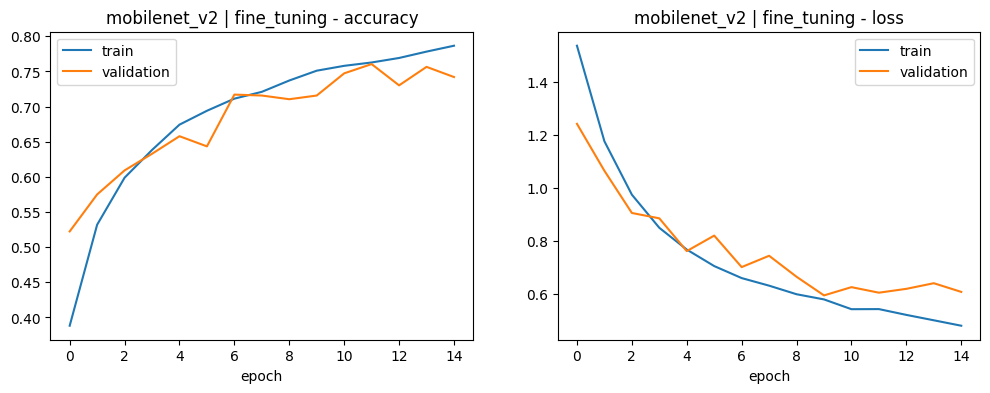

              precision    recall  f1-score   support

     Natural      0.608     0.938     0.738        48
       anger      0.463     0.725     0.565        69
        fear      0.385     0.833     0.526        30
         joy      0.989     0.800     0.885       350
     sadness      0.695     0.455     0.550       200
    surprise      0.566     0.889     0.691        63

    accuracy                          0.720       760
   macro avg      0.618     0.773     0.659       760
weighted avg      0.781     0.720     0.728       760



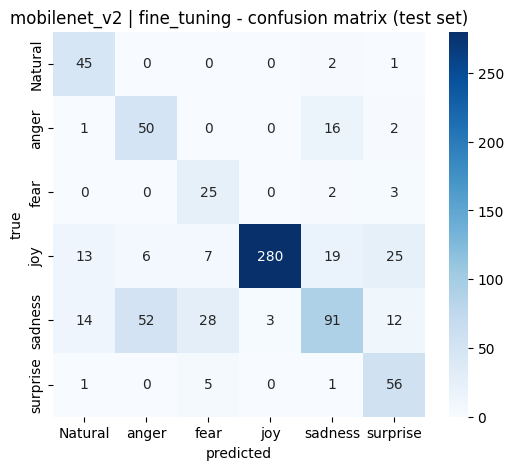


resnet50 | feature_extraction
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 173MB/s]


Epoch  1 | train loss 1.722 acc 0.299 | val loss 1.620 acc 0.442
Epoch  2 | train loss 1.552 acc 0.384 | val loss 1.467 acc 0.480
Epoch  3 | train loss 1.477 acc 0.421 | val loss 1.375 acc 0.463
Epoch  4 | train loss 1.440 acc 0.424 | val loss 1.503 acc 0.508
Epoch  5 | train loss 1.380 acc 0.447 | val loss 1.342 acc 0.474
Epoch  6 | train loss 1.413 acc 0.440 | val loss 1.388 acc 0.532
Epoch  7 | train loss 1.376 acc 0.456 | val loss 1.332 acc 0.512
Epoch  8 | train loss 1.319 acc 0.469 | val loss 1.288 acc 0.543
Epoch  9 | train loss 1.340 acc 0.471 | val loss 1.276 acc 0.420
Epoch 10 | train loss 1.307 acc 0.463 | val loss 1.394 acc 0.578
Epoch 11 | train loss 1.290 acc 0.481 | val loss 1.402 acc 0.543
Epoch 12 | train loss 1.276 acc 0.489 | val loss 1.432 acc 0.509
Epoch 13 | train loss 1.281 acc 0.495 | val loss 1.263 acc 0.461
Epoch 14 | train loss 1.275 acc 0.495 | val loss 1.315 acc 0.533
Epoch 15 | train loss 1.250 acc 0.493 | val loss 1.231 acc 0.516
Epoch 16 | train loss 1.2

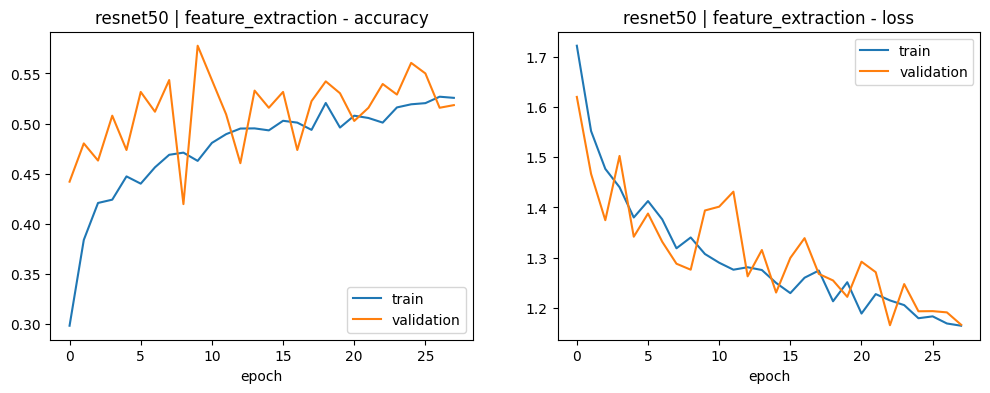

              precision    recall  f1-score   support

     Natural      0.294     0.625     0.400        48
       anger      0.407     0.478     0.440        69
        fear      0.233     0.667     0.345        30
         joy      0.764     0.703     0.732       350
     sadness      0.704     0.095     0.167       200
    surprise      0.239     0.540     0.332        63

    accuracy                          0.503       760
   macro avg      0.440     0.518     0.403       760
weighted avg      0.622     0.503     0.488       760



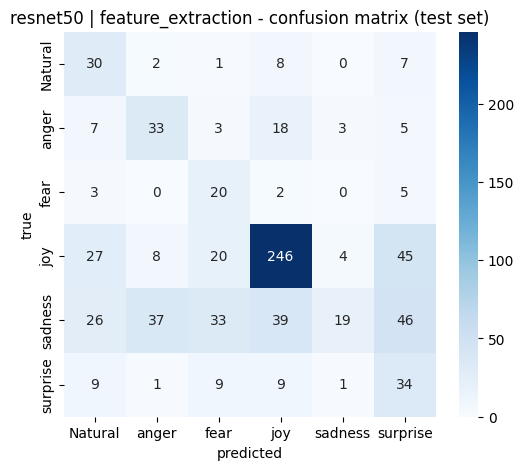


resnet50 | fine_tuning
Epoch  1 | train loss 1.286 acc 0.485 | val loss 0.897 acc 0.645
Epoch  2 | train loss 0.777 acc 0.680 | val loss 0.618 acc 0.739
Epoch  3 | train loss 0.628 acc 0.738 | val loss 0.759 acc 0.645
Epoch  4 | train loss 0.533 acc 0.764 | val loss 0.519 acc 0.780
Epoch  5 | train loss 0.467 acc 0.786 | val loss 0.459 acc 0.780
Epoch  6 | train loss 0.441 acc 0.802 | val loss 0.535 acc 0.768
Epoch  7 | train loss 0.426 acc 0.811 | val loss 0.420 acc 0.807
Epoch  8 | train loss 0.382 acc 0.814 | val loss 0.418 acc 0.812
Epoch  9 | train loss 0.359 acc 0.829 | val loss 0.432 acc 0.808
Epoch 10 | train loss 0.345 acc 0.833 | val loss 0.422 acc 0.805
Epoch 11 | train loss 0.335 acc 0.840 | val loss 0.419 acc 0.799
Epoch 12 | train loss 0.338 acc 0.836 | val loss 0.468 acc 0.801
Epoch 13 | train loss 0.329 acc 0.843 | val loss 0.475 acc 0.817
Early stopping.


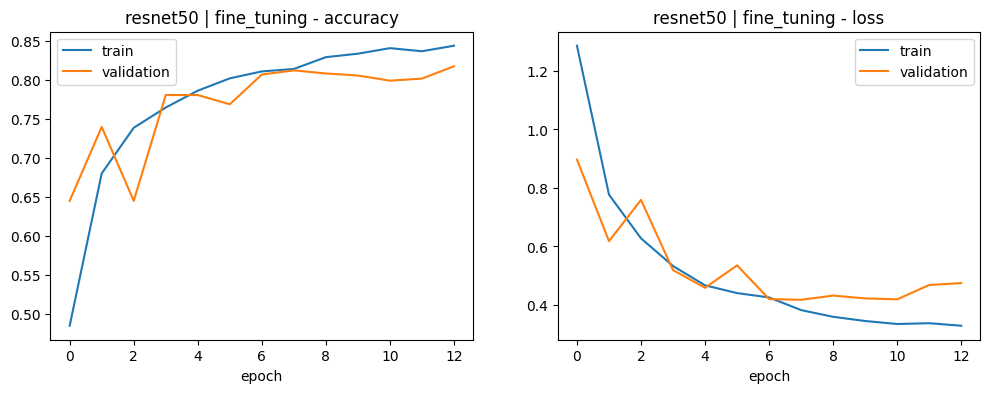

              precision    recall  f1-score   support

     Natural      0.894     0.875     0.884        48
       anger      0.491     0.826     0.616        69
        fear      0.433     0.867     0.578        30
         joy      1.000     0.940     0.969       350
     sadness      0.750     0.525     0.618       200
    surprise      0.838     0.905     0.870        63

    accuracy                          0.811       760
   macro avg      0.734     0.823     0.756       760
weighted avg      0.846     0.811     0.816       760



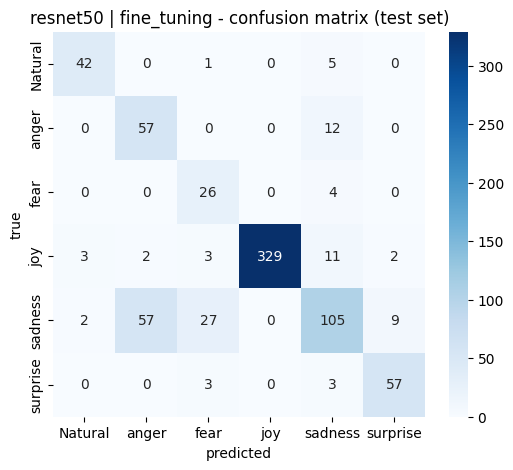


efficientnet_b0 | feature_extraction
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 130MB/s] 


Epoch  1 | train loss 1.660 acc 0.322 | val loss 1.547 acc 0.425
Epoch  2 | train loss 1.481 acc 0.408 | val loss 1.464 acc 0.482
Epoch  3 | train loss 1.405 acc 0.439 | val loss 1.396 acc 0.445
Epoch  4 | train loss 1.354 acc 0.459 | val loss 1.372 acc 0.509
Epoch  5 | train loss 1.332 acc 0.462 | val loss 1.311 acc 0.518
Epoch  6 | train loss 1.296 acc 0.475 | val loss 1.297 acc 0.513
Epoch  7 | train loss 1.272 acc 0.486 | val loss 1.262 acc 0.549
Epoch  8 | train loss 1.253 acc 0.489 | val loss 1.257 acc 0.554
Epoch  9 | train loss 1.244 acc 0.495 | val loss 1.213 acc 0.534
Epoch 10 | train loss 1.226 acc 0.496 | val loss 1.211 acc 0.525
Epoch 11 | train loss 1.200 acc 0.503 | val loss 1.198 acc 0.555
Epoch 12 | train loss 1.217 acc 0.489 | val loss 1.179 acc 0.536
Epoch 13 | train loss 1.211 acc 0.508 | val loss 1.165 acc 0.539
Epoch 14 | train loss 1.212 acc 0.509 | val loss 1.139 acc 0.538
Epoch 15 | train loss 1.199 acc 0.499 | val loss 1.158 acc 0.553
Epoch 16 | train loss 1.2

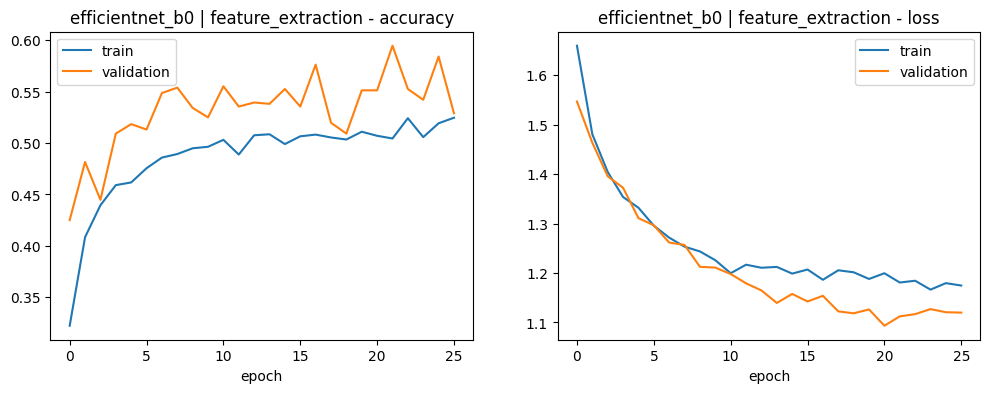

              precision    recall  f1-score   support

     Natural      0.352     0.521     0.420        48
       anger      0.388     0.754     0.512        69
        fear      0.333     0.733     0.458        30
         joy      0.851     0.634     0.727       350
     sadness      0.663     0.285     0.399       200
    surprise      0.310     0.698     0.429        63

    accuracy                          0.555       760
   macro avg      0.483     0.604     0.491       760
weighted avg      0.662     0.555     0.566       760



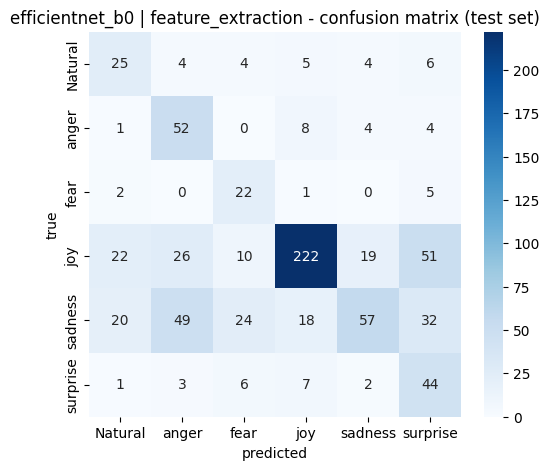


efficientnet_b0 | fine_tuning
Epoch  1 | train loss 1.694 acc 0.305 | val loss 1.550 acc 0.467
Epoch  2 | train loss 1.452 acc 0.441 | val loss 1.349 acc 0.514
Epoch  3 | train loss 1.289 acc 0.500 | val loss 1.209 acc 0.574
Epoch  4 | train loss 1.152 acc 0.547 | val loss 1.100 acc 0.588
Epoch  5 | train loss 1.046 acc 0.586 | val loss 1.005 acc 0.618
Epoch  6 | train loss 0.951 acc 0.617 | val loss 0.933 acc 0.663
Epoch  7 | train loss 0.893 acc 0.632 | val loss 0.853 acc 0.674
Epoch  8 | train loss 0.832 acc 0.662 | val loss 0.808 acc 0.680
Epoch  9 | train loss 0.793 acc 0.669 | val loss 0.778 acc 0.678
Epoch 10 | train loss 0.740 acc 0.686 | val loss 0.725 acc 0.703
Epoch 11 | train loss 0.730 acc 0.702 | val loss 0.713 acc 0.703
Epoch 12 | train loss 0.695 acc 0.705 | val loss 0.676 acc 0.718
Epoch 13 | train loss 0.656 acc 0.714 | val loss 0.680 acc 0.712
Epoch 14 | train loss 0.660 acc 0.721 | val loss 0.652 acc 0.738
Epoch 15 | train loss 0.629 acc 0.727 | val loss 0.634 acc 

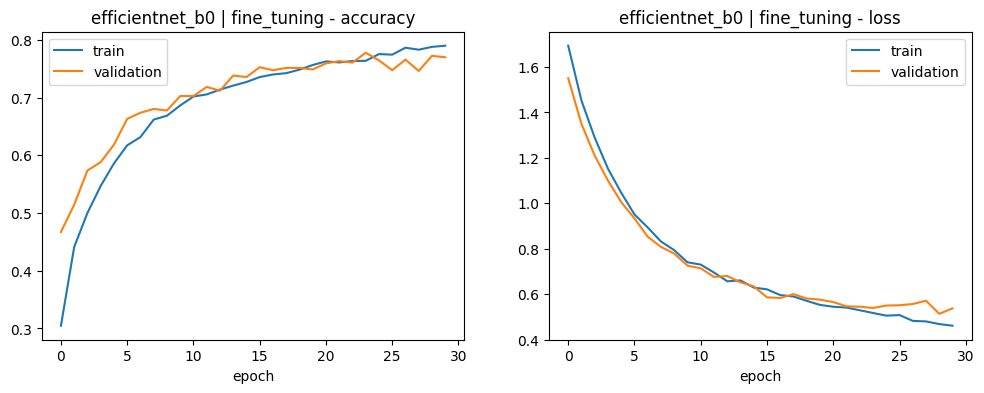

              precision    recall  f1-score   support

     Natural      0.657     0.958     0.780        48
       anger      0.464     0.928     0.618        69
        fear      0.441     0.867     0.584        30
         joy      0.975     0.891     0.931       350
     sadness      0.844     0.405     0.547       200
    surprise      0.662     0.810     0.729        63

    accuracy                          0.763       760
   macro avg      0.674     0.810     0.698       760
weighted avg      0.827     0.763     0.762       760



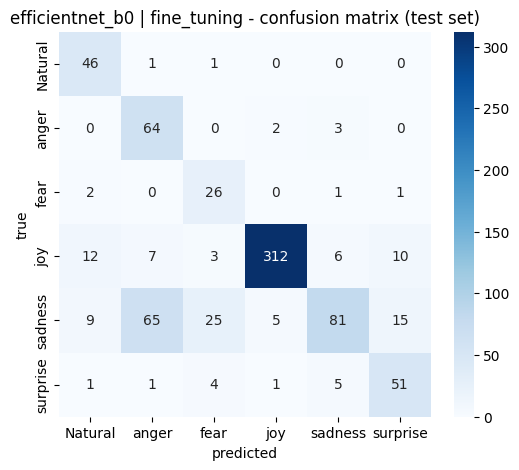

In [ ]:
results = []
for name in MODEL_NAMES:
    for mode in ["feature_extraction", "fine_tuning"]:
        title = f"{name} | {mode}"
        print("\n" + "=" * 70 + "\n" + title + "\n" + "=" * 70)

        model = build_model(name, mode)
        lr = LR_FEATURE_EXTRACTION if mode == "feature_extraction" else LR_FINE_TUNING
        history, train_time = train_model(model, lr)

        labels, preds, test_time = evaluate(model)
        show_results(title, history, labels, preds)

        report = classification_report(labels, preds, output_dict=True, zero_division=0)
        results.append({
            "Model": name, "Mode": mode,
            "Epochs run": len(history["train_loss"]),
            "Test accuracy": report["accuracy"],
            "Precision (macro)": report["macro avg"]["precision"],
            "Recall (macro)": report["macro avg"]["recall"],
            "F1 (macro)": report["macro avg"]["f1-score"],
            "Training time (s)": train_time,
            "Testing time (s)": test_time,
        })
        del model
        torch.cuda.empty_cache()

## Step 9 · Summary table of all 6 runs

In [ ]:
summary = pd.DataFrame(results).round(4)
display(summary)
summary.to_csv("summary_6_runs.csv", index=False)   # download this file from the Colab sidebar if you want it

best = summary.sort_values("F1 (macro)", ascending=False).iloc[0]
print("Best run:", best["Model"], "-", best["Mode"], "| macro F1 =", best["F1 (macro)"])

,Model,Mode,Epochs run,Test accuracy,Precision (macro),Recall (macro),F1 (macro),Training time (s),Testing time (s)
0,mobilenet_v2,feature_extraction,15,0.4500,0.4076,0.4948,0.4028,376.0651,1.5971
1,mobilenet_v2,fine_tuning,15,0.7197,0.6176,0.7732,0.6591,360.0470,1.5774
2,resnet50,feature_extraction,28,0.5026,0.4402,0.5179,0.4027,795.0598,2.7180
3,resnet50,fine_tuning,13,0.8105,0.7344,0.8229,0.7559,431.0078,2.9287
4,efficientnet_b0,feature_extraction,26,0.5553,0.4828,0.6042,0.4909,619.8880,1.5612
5,efficientnet_b0,fine_tuning,30,0.7632,0.6738,0.8097,0.6983,748.3634,1.7161


Best run: resnet50 - fine_tuning | macro F1 = 0.7559
